# AI Job Posting Insights

#### Analyze trend in AI job postings using Python libraries to uncover salary patterns and industry insights

## Libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load Dataset

In [5]:
data = pd.read_csv("ai_job_dataset.csv")
data.head(2)

,job_id,job_title,salary_usd,salary_currency,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry,posting_date,application_deadline,job_description_length,benefits_score,company_name
0,AI00001,AI Research Scientist,90376,USD,SE,CT,China,M,China,50,"Tableau, PyTorch, Kubernetes, Linux, NLP",Bachelor,9,Automotive,2024-10-18,2024-11-07,1076,5.9,Smart Analytics
1,AI00002,AI Software Engineer,61895,USD,EN,CT,Canada,M,Ireland,100,"Deep Learning, AWS, Mathematics, Python, Docker",Master,1,Media,2024-11-20,2025-01-11,1268,5.2,TechCorp Inc


# Data Processing

In [8]:
# Changed type to datetime
data["posting_date"] = pd.to_datetime(data["posting_date"])
data["application_deadline"] = pd.to_datetime(data["application_deadline"])

In [9]:
# Adding Job posting year

data["posting_year"] = data["posting_date"].dt.year
data.head(3)

,job_id,job_title,salary_usd,salary_currency,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry,posting_date,application_deadline,job_description_length,benefits_score,company_name,posting_year
0,AI00001,AI Research Scientist,90376,USD,SE,CT,China,M,China,50,"Tableau, PyTorch, Kubernetes, Linux, NLP",Bachelor,9,Automotive,2024-10-18,2024-11-07,1076,5.9,Smart Analytics,2024
1,AI00002,AI Software Engineer,61895,USD,EN,CT,Canada,M,Ireland,100,"Deep Learning, AWS, Mathematics, Python, Docker",Master,1,Media,2024-11-20,2025-01-11,1268,5.2,TechCorp Inc,2024
2,AI00003,AI Specialist,152626,USD,MI,FL,Switzerland,L,South Korea,0,"Kubernetes, Deep Learning, Java, Hadoop, NLP",Associate,2,Education,2025-03-18,2025-04-07,1974,9.4,Autonomous Tech,2025


# EDA Process

In [11]:
# Average Salary of each job
gp = data.groupby("job_title").agg({"salary_usd":"mean"})
gp.astype(int)

,salary_usd
job_title,
AI Architect,117436
AI Consultant,113671
AI Product Manager,114680
AI Research Scientist,117897
AI Software Engineer,114273
AI Specialist,120570
Autonomous Systems Engineer,111396
Computer Vision Engineer,113472
Data Analyst,111321


In [12]:
gp2 = data.groupby("industry").agg({"job_id":"count"})
gp2

,job_id
industry,
Automotive,1020
Consulting,1020
Education,956
Energy,976
Finance,984
Gaming,967
Government,998
Healthcare,997
Manufacturing,962


In [13]:
gp3 = data.groupby("company_location").agg({"job_id":"count"})
gp3

,job_id
company_location,
Australia,732
Austria,765
Canada,769
China,763
Denmark,778
Finland,733
France,769
Germany,814
India,754


## Descriptive statistics

In [15]:
# Select Numerical column
num_data = data.select_dtypes(include=['int']).copy()
num_data = num_data.drop("job_description_length",axis=1)

num_data.describe()

,salary_usd,remote_ratio,years_experience,posting_year
count,15000.000000,15000.000000,15000.000000,15000.000000
mean,115348.965133,49.483333,6.253200,2024.244533
std,60260.940438,40.812712,5.545768,0.429824
min,32519.000000,0.000000,0.000000,2024.000000
25%,70179.750000,0.000000,2.000000,2024.000000
50%,99705.000000,50.000000,5.000000,2024.000000
75%,146408.500000,100.000000,10.000000,2024.000000
max,399095.000000,100.000000,19.000000,2025.000000


## Visualization

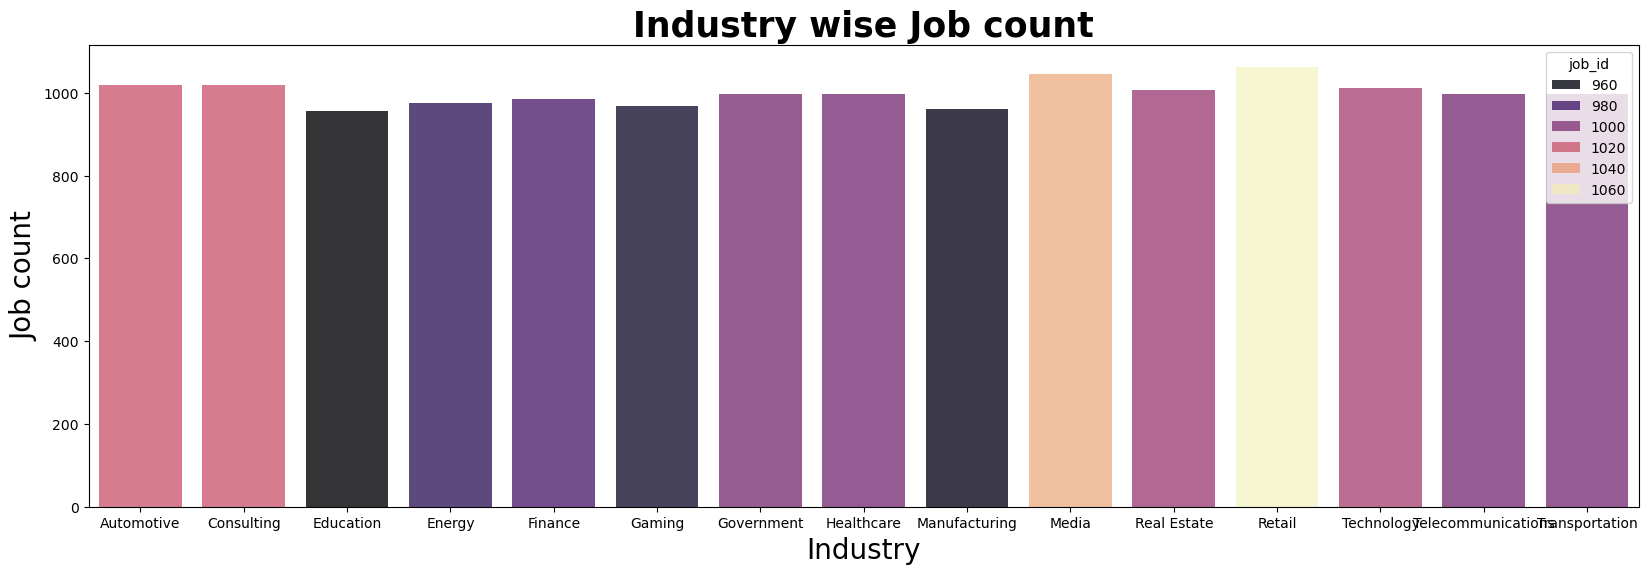

In [17]:
# Industry wise Job count

plt.figure(figsize=(20,6))
sns.barplot(data=gp2, x="industry", y="job_id",hue="job_id",palette="magma",alpha=0.8)
plt.ylabel("Job count",size=20)
plt.xlabel("Industry",size=20)
plt.title("Industry wise Job count",size=25,fontweight=600)
plt.show()

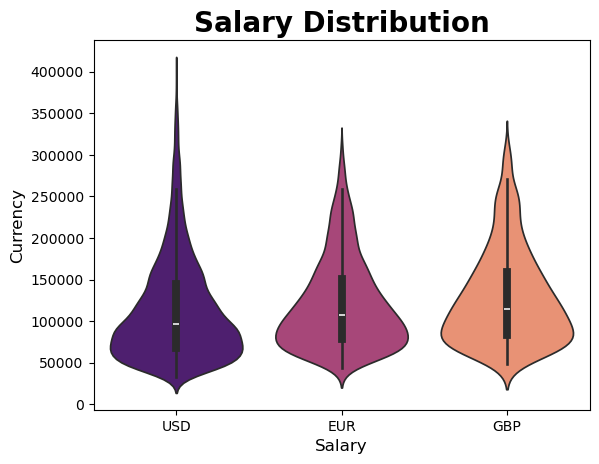

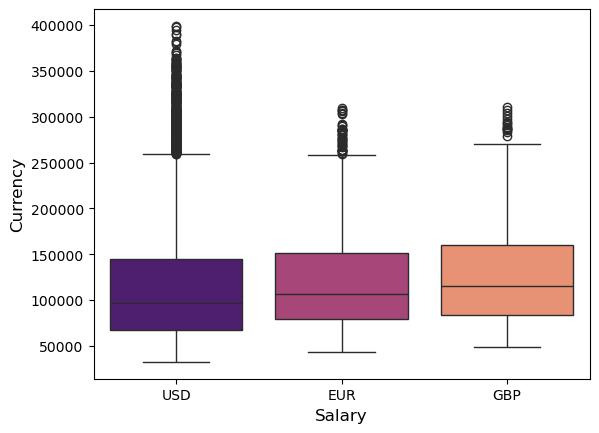

In [18]:
# Salary Distribution

sns.violinplot(data=data,y="salary_usd",x="salary_currency",hue="salary_currency",palette="magma")
plt.ylabel("Currency",size=12)
plt.xlabel("Salary",size=12)
plt.title("Salary Distribution",size=20,fontweight=600)
plt.show()

sns.boxplot(data=data,y="salary_usd",x="salary_currency",hue="salary_currency",palette="magma")
plt.ylabel("Currency",size=12)
plt.xlabel("Salary",size=12)
plt.show()

C:\Users\preneel\AppData\Local\Temp\ipykernel_12780\306014131.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=jp, x="posting_year", y="job_id",palette=colors)


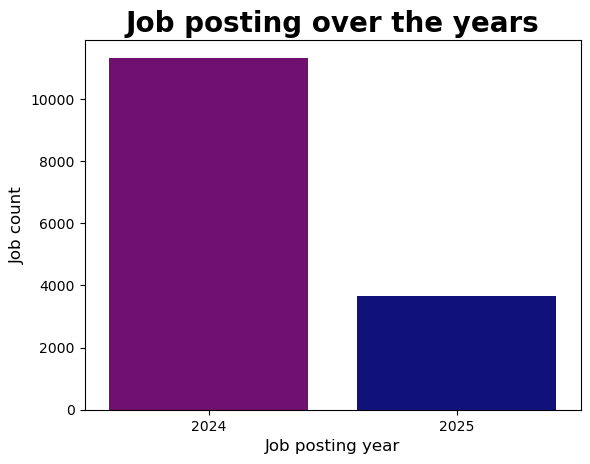

In [19]:
# job posting over the years

jp = data.groupby("posting_year").agg({"job_id":"count"})
colors = ["purple","darkblue"]
sns.barplot(data=jp, x="posting_year", y="job_id",palette=colors)
plt.ylabel("Job count",size=12)
plt.xlabel("Job posting year",size=12)
plt.title("Job posting over the years",size=20,fontweight=600)
plt.show()

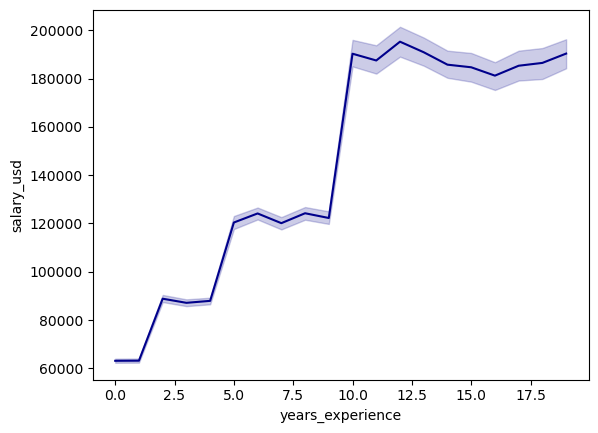

In [20]:
# Relation between Salary and Experience

sns.lineplot(data=data, x="years_experience", y="salary_usd",color="darkblue")
plt.show()

## Insights

- **Demand Trends** : The data shows a significant increase in job posting related to AI and ML roles over recent years.
- **Experience** : We can clearly see that salary is depending on the years of experience
- **Salary Insights** : By doing salary distribution we can conclude that most of the salary is ranging from 60k to 140k.

## Conclusion

This project explored the AI job market through data analysis and visualization. The finding confirms robust growth in AI job opportunities, importanace of technical skills like Python and Machine learning frameworks.

Overall, this analysis offers useful guidance for individuals seeking AI-related roles. Despite some limitations such as dataset size and scope, the project successfully highlights key trends shaping the AI employment landscape.

## Future Work

- **Deeper Skill Analysis** : Using NLP to exract and categorize specific skills mentioned in required skills.
- **Predictive Modeling** : Developing models to dorecast AI job market trend or salary growth on historical data.
- **Comparative Analysis** : Comparing AI job market trends across different industies or countries.